# Mean-variance Portfolio Optimization with a Neural Network

| Stage | Research question | Outputs |
|---|---|---|
| 1 | How do equal weighting, minimum variance, and mean–variance portfolios with and without mean shrinkage perform out of sample? | Weights at the first rebalance, portfolio wealth after trading costs, Sharpe ratios, portfolio turnover, and maximum ETF weights. |
| 2 | How quickly and accurately can a neural network approximate the mean–variance optimizer? | Objective gaps, constraint feasibility, and measured time per allocation for the network and solver under two settings: long-only and long-only with a turnover limit. |
| 3 | Does training a return predictor on portfolio utility through a differentiable optimizer improve out-of-sample performance? | Backtests that compare decision-focused learning, predict-then-optimize, and traditional strategies on the same test dates after trading costs. Results are reported for three random seeds. |

## Stage 1 · Constructing Portfolio with Statistical methods

### 1.1 Preparation

In [3]:
%pip install -q scikit-learn==1.8.0 torch==2.8.0 cvxpy==1.9.2 cvxpylayers==1.2.0 yfinance==1.8.0 pandas-market-calendars==5.6.1

Note: you may need to restart the kernel to use updated packages.


In [1]:
from pathlib import Path
import hashlib
import json

import cvxpy as cp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.covariance import LedoitWolf

ROOT = Path.cwd()
output = ROOT / "results" / "us_sector_etfs"
output.mkdir(parents=True, exist_ok=True)

### 1.2 Prepare for ETF data

In [2]:
from datetime import datetime, timezone
from tempfile import TemporaryDirectory
import pandas_market_calendars as mcal
import yfinance as yf

tickers = ["XLB", "XLE", "XLF", "XLI", "XLK", "XLP", "XLU", "XLV", "XLY"]
start_date, end_date = "2010-01-01", "2025-12-31"
download_start = pd.Timestamp(start_date) - pd.Timedelta(days=7)
download_end = pd.Timestamp(end_date) + pd.Timedelta(days=1)

data_dir = ROOT / "data"
prices_path = data_dir / "us_sector_etfs_prices.csv"
returns_path = data_dir / "us_sector_etfs.csv"
metadata_path = data_dir / "us_sector_etfs.json"
data_spec = {
    "source": "https://finance.yahoo.com/", "dataset": "US sector ETFs", "tickers": tickers,
    "requested_start": start_date, "requested_end": end_date,
    "price_adjustment": "yfinance auto_adjust=True: split- and dividend-adjusted Close",
}

In [3]:
# Adjusted closing price

cached = metadata_path.is_file()
if cached:
    provenance = json.loads(metadata_path.read_text())
    if any(provenance.get(key) != value for key, value in data_spec.items()):
        raise ValueError("The cached ETF list, data range, or price adjustment settings do not match the current configuration")
    for path, key in [(prices_path, "prices_sha256"), (returns_path, "csv_sha256")]:
        if hashlib.sha256(path.read_bytes()).hexdigest() != provenance[key]:
            raise ValueError(f"Cache checksum mismatch for：{path.name}")
    prices = pd.read_csv(prices_path, index_col="date", parse_dates=True)
else:
    quotes = yf.download(tickers, start=download_start, end=download_end, interval="1d",
                         auto_adjust=True, back_adjust=False, repair=False, keepna=True,
                         actions=False, threads=False, progress=False, group_by="column",
                         multi_level_index=True, timeout=30)
    if quotes is None or quotes.empty or "Close" not in quotes.columns.get_level_values(0):
        raise RuntimeError("Yahoo Finance did not return adjusted price data. Check your network connection and try again.")
    prices = quotes["Close"].reindex(columns=tickers)
    prices.index = pd.to_datetime(prices.index).tz_localize(None)
    prices = prices.rename_axis(index="date", columns=None)

In [4]:
# Calculate daily return from the closing price: 
# (today's adjusted closing price/the previous trading day's adjusted closing price) -1
sessions = mcal.get_calendar("NYSE").valid_days(download_start, end_date).tz_localize(None)
prior_session = sessions[sessions < pd.Timestamp(start_date)][-1]
expected_dates = sessions[sessions >= prior_session]

if list(prices.columns) != tickers or prices.index.has_duplicates or not prices.index.is_monotonic_increasing:
    raise ValueError("The ETF columns or trading date order are incorrect")
if not np.isfinite(prices.to_numpy()).all() or (prices <= 0).any().any():
    raise ValueError("Adjusted ETF prices must be finite and positive for every ETF on every trading day.")
window_prices = prices.loc[prior_session:end_date]
if not window_prices.index.equals(expected_dates):
    raise ValueError("Price dates do not match the NYSE trading calendar. Check for missing or extra dates.")
calculated = window_prices.pct_change(fill_method=None).iloc[1:]
if not np.isfinite(calculated.to_numpy()).all() or (calculated <= -1).any().any():
    raise ValueError("Daily return must be finite and greater than -100%。")

coverage = {"start": str(calculated.index[0].date()), "end": str(calculated.index[-1].date()),
            "rows": len(calculated)}
if cached:
    returns = pd.read_csv(returns_path, index_col="date", parse_dates=True)
    pd.testing.assert_frame_equal(returns, calculated, check_freq=False, atol=1e-12, rtol=1e-10)
    if any(provenance.get(key) != value for key, value in coverage.items()):
        raise ValueError("The start date, end date, or row count recorded in the cache is incorrect.")
else:
    returns = calculated

In [5]:
# Save the download daily return data
if not cached:
    import fcntl

    data_dir.mkdir(parents=True, exist_ok=True)
    with TemporaryDirectory(dir=data_dir) as staging:
        temp = Path(staging)
        prices.to_csv(temp / prices_path.name)
        returns.to_csv(temp / returns_path.name)
        provenance = {
            **data_spec, **coverage, "prices_file": prices_path.name,
            "return_definition": "adjusted Close pct_change(fill_method=None), decimal daily returns",
            "downloaded_at_utc": datetime.now(timezone.utc).isoformat(), "yfinance_version": yf.__version__,
            "prices_sha256": hashlib.sha256((temp / prices_path.name).read_bytes()).hexdigest(),
            "csv_sha256": hashlib.sha256((temp / returns_path.name).read_bytes()).hexdigest(),
        }
        (temp / metadata_path.name).write_text(json.dumps(provenance, indent=2) + "\n")
        with (data_dir / ".us_sector_etfs.lock").open("a") as lock:
            fcntl.flock(lock, fcntl.LOCK_EX)
            if not metadata_path.exists():
                for path in (prices_path, returns_path, metadata_path):
                    (temp / path.name).replace(path)
            elif json.loads(metadata_path.read_text())["csv_sha256"] != provenance["csv_sha256"]:
                raise RuntimeError("Another kernel just saved a different version of the market data. Please rerun from the data-loading cell.")
            else:
                provenance = json.loads(metadata_path.read_text())

print(f"{len(returns):,} trading days，{returns.shape[1]} ETFs，{coverage['start']} to {coverage['end']}")
display(returns.head())

4,024 trading days，9 ETFs，2010-01-04 to 2025-12-31


,XLB,XLE,XLF,XLI,XLK,XLP,XLU,XLV,XLY
date,,,,,,,,,
2010-01-04,0.031221,0.031573,0.020139,0.019072,0.014828,0.007555,0.001934,0.017380,0.007726
2010-01-05,0.003234,0.008162,0.018380,0.003531,-0.001289,0.000375,-0.011905,-0.009807,0.003667
2010-01-06,0.016994,0.011975,0.002005,0.002111,-0.011188,-0.000750,0.005861,0.010224,0.001328
2010-01-07,-0.007779,-0.001500,0.021348,0.010885,-0.003916,0.000000,-0.004532,0.003479,0.008292
2010-01-08,0.013937,0.006510,-0.005879,0.015978,0.006553,-0.003376,-0.000976,0.001576,-0.000329


### 1.3 Estimate Returns and Risk Before Each Rebalance

For each rebalancing date `start`, use the preceding 126 trading days. Multiply each ETF’s average daily return by 252 to estimate its annualized return. Use Ledoit–Wolf to estimate the daily covariance matrix, then multiply it by 252 to annualize it. Hold the portfolio for 21 trading days starting on the rebalancing date and evaluate its realized returns.

In [6]:
# Each time, estimate returns and risk using the past 126 trading days, 
# calculate the weights, and then hold the positions for 21 trading days.
lookback, horizon = 126, 21
train_periods, validation_periods, test_periods = 60, 12, 12
gamma, cost_bps = 5.0, 10.0 ## risk aversion coefficient and transaction fees
n_assets = len(tickers)
if lookback < 63 or horizon < 2 or min(train_periods, validation_periods, test_periods) < 1:
    raise ValueError("Use at least 63 trading days of history, a holding period of at least,"
                     "2 trading days, and positive training, validation, and test lengths.")
if not np.isfinite([gamma, cost_bps]).all() or gamma <= 0 or cost_bps < 0:
    raise ValueError("The risk aversion coefficient must be positive, and the transaction cost rate must be nonnegative.")

starts = np.arange(lookback, len(returns) - horizon + 1, horizon)
# Reserve the first 60 holding periods for Stage 3 training and the next 12
# for validation, so both backtests use the same evaluation dates.
first_test = train_periods + validation_periods
if len(starts) <= first_test:
    raise ValueError("Insufficient data for the lookback window, training, validation, and at least one out-of-sample holding period.")
# Expected Annualized Return,Covariance factor, Actual returns over the next 21 days
means, factors, future = [], [], []
for start in starts:
    history = returns.iloc[start - lookback:start].to_numpy()
    means.append(252 * history.mean(axis=0))
    covariance = 252 * LedoitWolf().fit(history).covariance_
    values, vectors = np.linalg.eigh(covariance)
    if values.min() < -1e-10:
        raise ValueError("The estimated covariance matrix must be positive semidefinite.")
    # F.T @ F = covariance
    factors.append(np.sqrt(np.maximum(values, 0))[:, None] * vectors.T)
    future.append(returns.iloc[start:start + horizon].to_numpy())
means, factors, future = np.array(means), np.array(factors), np.array(future)

first_day = starts[first_test]
print("First out-of-sample rebalancing date", returns.index[first_day].date())
print("Estimation window", returns.index[first_day-lookback].date(), "to", returns.index[first_day-1].date())
display(pd.Series(means[first_test], index=tickers, name="Expected Annualized Return").round(4))

First out-of-sample rebalancing date 2016-07-07
Estimation window 2016-01-06 to 2016-07-06


XLB    0.1758
XLE    0.2875
XLF   -0.0439
XLI    0.1661
XLK    0.0967
XLP    0.2230
XLU    0.4356
XLV    0.0809
XLY    0.0861
Name: Expected Annualized Return, dtype: float64

### 1.4 Compute Portfolio Weights at Each Rebalance

Minimize $\gamma w^T\Sigma w-\mu^Tw$ subject to long-only and full-investment constraints. Each weight must be nonnegative, and the weights must sum to one.

The equal-weight strategy assigns $1/9$ to each ETF. The minimum-variance strategy sets the expected return term to zero, while classical MVO uses the historical mean returns. The mean-shrinkage baseline scales each historical mean to 25% of its original value. Both MVO baselines use the same Ledoit–Wolf covariance, risk aversion, and constraints.

In [7]:
weight_variable = cp.Variable(n_assets)
mean_parameter = cp.Parameter(n_assets)
factor_parameter = cp.Parameter((n_assets, n_assets))
objective = gamma * cp.sum_squares(factor_parameter @ weight_variable) - mean_parameter @ weight_variable
allocation_problem = cp.Problem(cp.Minimize(objective), [weight_variable >= 0, cp.sum(weight_variable) == 1])

historical_mean_scale = 0.25
mean_scales = {
    "minimum_variance": 0.0,
    "classical_mvo": 1.0,
    "shrunk_mean_mvo": historical_mean_scale,
}
baseline_names = ["equal_weight", *mean_scales]
baseline_targets = {name: [] for name in baseline_names}
for period in range(first_test, len(starts)):
    baseline_targets["equal_weight"].append(np.full(n_assets, 1 / n_assets))
    factor_parameter.value = factors[period]
    for name, mean_scale in mean_scales.items():
        mean_parameter.value = mean_scale * means[period]
        allocation_problem.solve(solver=cp.CLARABEL, warm_start=True)
        if allocation_problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            raise RuntimeError(f"Optimization failed for {name} in period {period}.")
        weights = weight_variable.value
        assert np.isfinite(weights).all() and weights.min() >= -2e-4 and abs(weights.sum() - 1) <= 2e-4
        weights = np.maximum(weights, 0)
        baseline_targets[name].append(weights / weights.sum())
baseline_targets = {name: np.array(rows) for name, rows in baseline_targets.items()}
first_weights = pd.DataFrame({name: baseline_targets[name][0] for name in baseline_names}, index=tickers)
display(first_weights.round(4))

,equal_weight,minimum_variance,classical_mvo,shrunk_mean_mvo
XLB,0.1111,0.0000,0.0,0.0000
XLE,0.1111,0.0000,0.0,0.0056
XLF,0.1111,0.0000,0.0,0.0000
XLI,0.1111,0.0199,0.0,0.0592
XLK,0.1111,0.0000,0.0,0.0000
XLP,0.1111,0.2969,0.0,0.0860
XLU,0.1111,0.4201,1.0,0.7427
XLV,0.1111,0.2353,0.0,0.1066
XLY,0.1111,0.0279,0.0,0.0000


### 1.5 Hold for 21 Trading Days, Then Rebalance and Deduct Trading Costs

Each strategy starts in cash. The initial purchases and all subsequent buys and sells incur a fee of 10 basis points (0.10%) of the amount traded. During the holding period, the portfolio weights drift as ETF returns differ. At the next rebalance, turnover is calculated by comparing the drifted weights with the new target weights.

In [8]:
rebalance_dates = returns.index[starts[first_test:]]
test_dates = returns.index[starts[first_test]:starts[-1] + horizon]
targets_to_test = baseline_targets
daily_values, trade_values = {}, {}
for name, targets in targets_to_test.items():
    previous = np.zeros(n_assets)
    net_days, turnovers = [], []
    for target, period_returns in zip(targets, future[first_test:], strict=True):
        turnover = np.abs(target - previous).sum()
        fee = turnover * cost_bps / 10_000
        assert 0 <= fee < 1
        positions = target * np.cumprod(1 + period_returns, axis=0)
        wealth = positions.sum(axis=1)
        net = wealth / np.r_[1.0, wealth[:-1]] - 1
        net[0] = (1 - fee) * (1 + net[0]) - 1
        previous = positions[-1] / wealth[-1]
        net_days.extend(net)
        turnovers.append(turnover)
    daily_values[name] = net_days
    trade_values[name] = turnovers
baseline_daily = pd.DataFrame(daily_values, index=test_dates)
baseline_turnover = pd.DataFrame(trade_values, index=rebalance_dates)

### 1.6 Compare the results in Stage 1

2016-07-07 to 2025-12-11, with a total of 2373 out-of-sample trading days


,cagr,annual_volatility,sharpe_rf_zero,max_drawdown,annual_utility,annual_turnover,maximum_target_weight
equal_weight,0.1289,0.1726,0.7890,-0.3670,-0.0128,0.4297,0.1111
minimum_variance,0.0773,0.1450,0.5866,-0.3021,-0.0200,2.8368,0.7295
classical_mvo,0.0471,0.1972,0.3323,-0.3823,-0.1289,11.0201,1.0000
shrunk_mean_mvo,0.0529,0.1597,0.4028,-0.3232,-0.0632,6.8286,0.7761


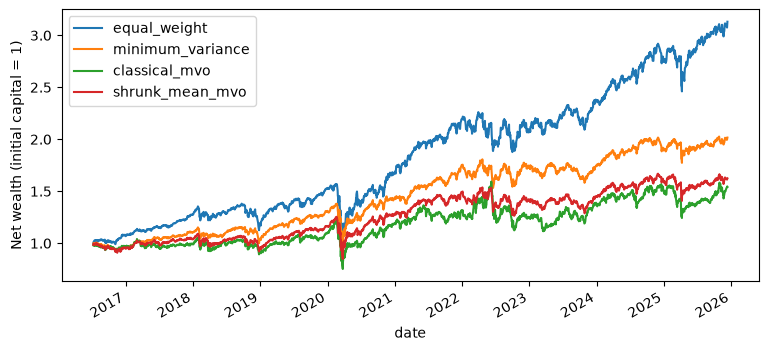

In [9]:
daily, turnover_table, all_targets = baseline_daily, baseline_turnover, baseline_targets
wealth = (1 + daily).cumprod()
annual_mean = daily.mean() * 252
annual_variance = daily.var(ddof=0) * 252
peak = wealth.cummax().clip(lower=1.0)
summary = pd.DataFrame({
    "cagr": wealth.iloc[-1] ** (252 / len(daily)) - 1,
    "annual_volatility": np.sqrt(annual_variance),
    "sharpe_rf_zero": annual_mean / np.sqrt(annual_variance).replace(0, np.nan),
    "max_drawdown": (wealth / peak - 1).min(),
    "annual_utility": annual_mean - gamma * annual_variance,
    "annual_turnover": turnover_table.sum() * 252 / len(daily),
    "maximum_target_weight": pd.Series({name: targets.max() for name, targets in all_targets.items()}),
})
baseline_summary = summary.copy()
print(f"{test_dates[0].date()} to {test_dates[-1].date()}, with a total of {len(daily)} out-of-sample trading days")
display(baseline_summary.round(4))
wealth.plot(ylabel="Net wealth (initial capital = 1)", figsize=(9, 4))
plt.show()

## Stage 2 · Approximate Optimal Weights with a Neural Network

Train a neural network to approximate the portfolio weights produced by the exact optimizer. The network takes historical ETF mean returns, covariance matrices, and simulated pre-trade portfolio weights as inputs. This experiment measures approximation error and computation time independently of return forecasting and portfolio backtesting.

Compare a long-only, fully invested portfolio with the same setting subject to an additional $L_1$ turnover cap of 0.4.

In [10]:
import math
from time import perf_counter
import torch
from torch import nn
from IPython.display import display

torch.set_num_threads(1)
imitation_seed = 7
imitation_epochs = 150
train_count = 512
test_count = 128
train_fraction = 0.8
cases = {"long_only": None, "turnover_0.4": 0.4}
n_assets = returns.shape[1]
assert list(returns.columns) == list(tickers)
assert n_assets >= 2 and gamma > 0
assert returns.index.is_monotonic_increasing and not returns.index.has_duplicates
assert np.isfinite(returns.to_numpy()).all() and (returns.to_numpy() > -1).all()
rng = np.random.default_rng(imitation_seed)
amortized = {}

### 2.1 Optimization Problem Based on ETF Historical Data

First, the data is split chronologically: the initial 80% serves as the training set, and the subsequent 20% as the test set. For each segment, 126-day historical windows are constructed independently; the return for the "as-of" date itself is excluded from its corresponding historical window, and there is no overlap in historical observations between the training and test sets.

Next, 512 dates are sampled for the training set, followed by 128 dates for the test set, while strictly maintaining the original sequence of random number generation used in the experiment. Once sampled (without replacement), the dates are sorted.

In [11]:
boundary = int(len(returns) * train_fraction)
partitions = {"train": returns.iloc[:boundary], "test": returns.iloc[boundary:]}
moments = {}
metadata = {
    "instance_source": "market_rolling_history",
    "assets": list(tickers),
    "lookback": int(lookback),
    "train_fraction": train_fraction,
    "split_boundary": str(returns.index[boundary].date()),
    "previous_source": "indpendent Dirichlet simulation, not continuous market holdings",
    "partition_method": "split raw dates first; historical windows never cross the boundary",
}
for partition_name, count in (("train", train_count), ("test", test_count)):
    partition = partitions[partition_name]
    if len(partition) - lookback < count:
        raise ValueError(f"The {partition_name} partition does not contain enough eligible dates to sample {count} distinct dates.")
    ends = np.sort(rng.choice(np.arange(lookback, len(partition)), count, replace=False))
    window_means, covariances = [], []
    for end in ends:
        history = partition.iloc[end - lookback:end].to_numpy()
        window_means.append(history.mean(axis=0) * 252)
        covariances.append(LedoitWolf().fit(history).covariance_ * 252)
    moments[partition_name] = (np.asarray(window_means), np.asarray(covariances))
    metadata[f"{partition_name}_asof_dates"] = [str(partition.index[i].date()) for i in ends]
    metadata[f"{partition_name}_first_asof"] = str(partition.index[ends[0]].date())
    metadata[f"{partition_name}_last_asof"] = str(partition.index[ends[-1]].date())
    metadata[f"{partition_name}_history_first"] = str(partition.index[ends[0] - lookback].date())
    metadata[f"{partition_name}_history_last"] = str(partition.index[ends[-1] - 1].date())
assert metadata["train_history_last"] < metadata["test_history_first"]
print("Training as-of：", metadata["train_first_asof"], "to", metadata["train_last_asof"])
print("Test as-of：", metadata["test_first_asof"], "to", metadata["test_last_asof"])

Training as-of： 2010-07-19 to 2022-09-28
Test as-of： 2023-05-01 to 2025-12-23


Next, simulate each account’s fully invested portfolio before rebalancing. Draw a separate set of portfolio weights from a Dirichlet distribution for each problem instance. Each draw represents a starting portfolio for that instance rather than a point in a single account’s trading history. For a fair comparison, use the same market inputs and pre-trade weights in both constraint settings.

In [12]:
previous = {
    "train": rng.dirichlet(np.ones(n_assets), train_count),
    "test": rng.dirichlet(np.ones(n_assets), test_count),
}
for partition_name in ("train", "test"):
    assert (previous[partition_name] >= 0).all()
    np.testing.assert_allclose(previous[partition_name].sum(axis=1), 1)

### 2.2 Generate Labels with the Exact Solver

Define two reusable optimization problems, one for each constraint setting. Both minimize the portfolio’s annualized variance multiplied by the risk aversion coefficient, minus its expected annualized return. Represent the covariance matrix Σ using a factor F such that FᵀF = Σ. For the turnover-constrained problem, also impose an upper bound on the L1 distance between the target weights and the pre-trade weights.

In [13]:
problems = {}
mean_parameters = {}
factor_parameters = {}
previous_parameters = {}
weight_variables = {}
for setting, limit in cases.items():
    teacher_mean_parameter = cp.Parameter(n_assets)
    teacher_factor_parameter = cp.Parameter((n_assets, n_assets))
    previous_parameter = cp.Parameter(n_assets)
    teacher_weight_variable = cp.Variable(n_assets)
    objective = gamma * cp.sum_squares(teacher_factor_parameter @ teacher_weight_variable) - teacher_mean_parameter @ teacher_weight_variable
    constraints = [teacher_weight_variable >= 0, cp.sum(teacher_weight_variable) == 1]
    if limit is not None:
        constraints.append(cp.norm1(teacher_weight_variable - previous_parameter) <= limit)
    problems[setting] = cp.Problem(cp.Minimize(objective), constraints)
    mean_parameters[setting] = teacher_mean_parameter
    factor_parameters[setting] = teacher_factor_parameter
    previous_parameters[setting] = previous_parameter
    weight_variables[setting] = teacher_weight_variable

Use the exact solver to generate target portfolio weights for the training set and reference solutions for the test set. Before solving each problem, check that the covariance matrix has finite entries, is symmetric, and is positive semidefinite. After each solve, check the solver status and verify that the weights are nonnegative, sum to one, and satisfy the turnover limit when applicable. If the numerical errors are within tolerance, clip any small negative weights to zero and renormalize the weights to sum to one.

The reported label-generation time covers only the training labels.

In [14]:
teacher = {}
label_seconds = {}
for setting, limit in cases.items():
    teacher[setting] = {}
    for partition_name in ("train", "test"):
        window_means, covariances = moments[partition_name]
        rows = []
        started = perf_counter()
        for mean, covariance, prior in zip(window_means, covariances, previous[partition_name]):
            if not np.isfinite(mean).all() or not np.isfinite(covariance).all():
                raise ValueError("The optimization inputs contain non-finite values.")
            if not np.allclose(covariance, covariance.T, atol=1e-10, rtol=1e-8):
                raise ValueError("The covariance matrix must be symmetric.")
            eigenvalues, eigenvectors = np.linalg.eigh((covariance + covariance.T) / 2)
            if eigenvalues.min() < -1e-10:
                raise ValueError("The covariance matrix must be positive semidefinite.")
            mean_parameters[setting].value = mean
            factor_parameters[setting].value = np.sqrt(np.maximum(eigenvalues, 0))[:, None] * eigenvectors.T
            if limit is not None:
                prior_clean = np.maximum(prior, 0)
                prior_clean = prior_clean / prior_clean.sum()
                previous_parameters[setting].value = prior_clean
            problems[setting].solve(solver=cp.CLARABEL, warm_start=True)
            if problems[setting].status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
                raise RuntimeError(f"Optimization failed with solver status：{problems[setting].status}")
            solution = np.asarray(weight_variables[setting].value, dtype=float)
            if not np.isfinite(solution).all() or solution.min() < -2e-4 or abs(solution.sum() - 1) > 2e-4:
                raise RuntimeError("The solver returned infeasible portfolio weights.")
            solution = np.maximum(solution, 0)
            solution = solution / solution.sum()
            if limit is not None and np.abs(solution - prior_clean).sum() > limit + 2e-4:
                raise RuntimeError("The portfolio weights returned by the solver exceed turnover limit.")
            rows.append(solution)
        if partition_name == "train":
            label_seconds[setting] = perf_counter() - started
        teacher[setting][partition_name] = np.asarray(rows)
print("Training label generation time(seconds)：", label_seconds)

Training label generation time(seconds)： {'long_only': 0.25163591699674726, 'turnover_0.4': 0.26496479101479053}


### 2.3 Train a Neural Network to Predict Portfolio Weights

Concatenate the expected returns, the flattened covariance matrix, and the pre-trade portfolio weights, in that order, to form the network input. Use only the training instances to compute the mean and standard deviation of each input feature.

For each constraint setting, initialize the network with the same random seed and train it for 150 epochs. The network has two hidden layers of 64 units each, with ReLU activations and a softmax output layer. Softmax ensures that the portfolio weights are nonnegative and sum to one. If the proposed allocation exceeds the turnover limit, scale down the move from the pre-trade weights toward the proposed weights until it meets the limit. Apply the same rule during training and inference.

In [15]:
models, centers, scales, train_seconds = {}, {}, {}, {}
for setting, limit in cases.items():
    torch.manual_seed(imitation_seed)
    started = perf_counter()
    train_mean, train_covariance = moments["train"]
    inputs = np.concatenate([train_mean, train_covariance.reshape(train_count, -1), previous["train"]], axis=1)
    center = inputs.mean(axis=0)
    scale = np.maximum(inputs.std(axis=0), 1e-8)
    train_inputs_tensor = torch.tensor((inputs - center) / scale, dtype=torch.float32)
    target_weights_tensor = torch.tensor(teacher[setting]["train"], dtype=torch.float32)
    model = nn.Sequential(
        nn.Linear(2 * n_assets + n_assets**2, 64), nn.ReLU(),
        nn.Linear(64, 64), nn.ReLU(),
        nn.Linear(64, n_assets), nn.Softmax(dim=-1),
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
    model.train()
    for epoch in range(imitation_epochs):
        optimizer.zero_grad()
        prior_tensor = torch.tensor(inputs[:, -n_assets:], dtype=torch.float32)
        weight_tensor = model(train_inputs_tensor)
        if limit is not None:
            distance = (weight_tensor - prior_tensor).abs().sum(dim=-1, keepdim=True)
            fraction = (limit / distance.clamp_min(1e-12)).clamp(max=1)
            weight_tensor = prior_tensor + fraction * (weight_tensor - prior_tensor)
        loss = (weight_tensor - target_weights_tensor).square().mean()
        loss.backward()
        optimizer.step()
    model.eval()
    train_seconds[setting] = perf_counter() - started
    models[setting] = model
    centers[setting], scales[setting] = center, scale
    print(setting, "Final Training MSE：", float(loss.detach()), "Training Seconds：", train_seconds[setting])

long_only Final Training MSE： 0.003261629957705736 Training Seconds： 0.4844673339975998
turnover_0.4 Final Training MSE： 0.0015132990665733814 Training Seconds： 0.1927532920090016


Use the trained network to generate portfolio weights for unseen test instances and verify that the weights satisfy the applicable constraints. The training and test instances come from the same family of optimization problems, and all test dates are later than all training dates.

In [16]:
test_mean, test_covariance = moments["test"]
predictions = {}
for setting, limit in cases.items():
    test_inputs = np.concatenate([test_mean, test_covariance.reshape(test_count, -1), previous["test"]], axis=1)
    normalized = (test_inputs - centers[setting]) / scales[setting]
    with torch.no_grad():
        weight_tensor = models[setting](torch.tensor(normalized, dtype=torch.float32))
        prior_tensor = torch.tensor(previous["test"], dtype=torch.float32)
        if limit is not None:
            distance = (weight_tensor - prior_tensor).abs().sum(dim=-1, keepdim=True)
            fraction = (limit / distance.clamp_min(1e-12)).clamp(max=1)
            weight_tensor = prior_tensor + fraction * (weight_tensor - prior_tensor)
        weights = weight_tensor.numpy()
    assert np.isfinite(weights).all() and weights.min() >= -1e-7
    assert np.max(np.abs(weights.sum(axis=1) - 1)) < 1e-6
    if limit is not None:
        assert np.max(np.abs(weights - previous["test"]).sum(axis=1)) <= limit + 2e-6
    predictions[setting] = weights

### 2.4 Compare Objective Gaps

In [17]:
for setting, limit in cases.items():
    weights = predictions[setting]
    optimum = teacher[setting]["test"]
    network_objective = gamma * np.einsum("bi,bij,bj->b", weights, test_covariance, weights) - np.sum(test_mean * weights, axis=1)
    optimal_objective = gamma * np.einsum("bi,bij,bj->b", optimum, test_covariance, optimum) - np.sum(test_mean * optimum, axis=1)
    gap = network_objective - optimal_objective
    assert gap.min() >= -2e-5
    amortized[setting] = {
        "objective_gap_mean": float(gap.mean()),
        "objective_gap_p95": float(np.quantile(gap, 0.95)),
        "objective_gap_max": float(gap.max()),
        "weight_rmse": float(np.sqrt(np.mean((weights - optimum) ** 2))),
        "minimum_weight": float(weights.min()),
        "maximum_budget_error": float(np.max(np.abs(weights.sum(axis=1) - 1))),
        "turnover_limit": limit,
        "maximum_turnover": float(np.abs(weights - previous["test"]).sum(axis=1).max()),
    }

### 2.5 Measure Solver and Inference Time

Timing starts with the mean return vector, covariance matrix, and pre-trade portfolio weights for each instance. Neural network inference time includes assembling and standardizing the inputs, converting them to tensors, running the network, and enforcing the turnover limit when applicable. Solver time includes validating the inputs, computing the covariance factor, updating the problem parameters, solving the problem, and checking and cleaning up the resulting weights.

Run one warm-up for each method, then time both methods on the same 128 test instances. For each instance, time the network first and the solver second.

In [18]:
neural_times, solver_times = {}, {}
for setting, limit in cases.items():
    neural_times[setting], solver_times[setting] = [], []
    # The first run on test instance 0 is a warm-up and is excluded from the median.
    for trial, index in enumerate([0] + list(range(test_count))):
        mean = test_mean[index]
        covariance = test_covariance[index]
        prior = previous["test"][index]
        started = perf_counter()
        packed = np.concatenate([mean[None], covariance.reshape(1, -1), prior[None]], axis=1)
        normalized = (packed - centers[setting]) / scales[setting]
        with torch.no_grad():
            weight_tensor = models[setting](torch.tensor(normalized, dtype=torch.float32))
            prior_tensor = torch.tensor(prior[None], dtype=torch.float32)
            if limit is not None:
                distance = (weight_tensor - prior_tensor).abs().sum(dim=-1, keepdim=True)
                fraction = (limit / distance.clamp_min(1e-12)).clamp(max=1)
                weight_tensor = prior_tensor + fraction * (weight_tensor - prior_tensor)
            timed_weights = weight_tensor.numpy()
        neural_elapsed = perf_counter() - started

        started = perf_counter()
        mean = np.asarray(mean, dtype=float)
        covariance = np.asarray(covariance, dtype=float)
        if mean.shape != (n_assets,) or not np.isfinite(mean).all():
            raise ValueError("The expected return vector has an invalid shape or contains non-finite values.")
        if covariance.shape != (n_assets, n_assets) or not np.isfinite(covariance).all():
            raise ValueError("The covariance matrix has an invalid shape or contains non-finite values.")
        if not np.allclose(covariance, covariance.T, atol=1e-10, rtol=1e-8):
            raise ValueError("The covariance matrix must be symmetric.")
        eigenvalues, eigenvectors = np.linalg.eigh((covariance + covariance.T) / 2)
        if eigenvalues.min() < -1e-10:
            raise ValueError("The covariance matrix must be positive semidefinite.")
        mean_parameters[setting].value = mean
        factor_parameters[setting].value = np.sqrt(np.maximum(eigenvalues, 0))[:, None] * eigenvectors.T
        if limit is not None:
            prior_clean = np.asarray(prior, dtype=float)
            if not np.isfinite(prior_clean).all() or prior_clean.min() < -2e-4 or abs(prior_clean.sum() - 1) > 2e-4:
                raise ValueError("Pre-trade weights must be finite, nonnegative, and sum to one.")
            prior_clean = np.maximum(prior_clean, 0)
            prior_clean = prior_clean / prior_clean.sum()
            previous_parameters[setting].value = prior_clean
        problems[setting].solve(solver=cp.CLARABEL, warm_start=True)
        if problems[setting].status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
            raise RuntimeError("The exact solver failed during timing.")
        solution = np.asarray(weight_variables[setting].value, dtype=float)
        if not np.isfinite(solution).all() or solution.min() < -2e-4 or abs(solution.sum() - 1) > 2e-4:
            raise RuntimeError("The solver returned infeasible portfolio weights during timing.")
        solution = np.maximum(solution, 0)
        solution = solution / solution.sum()
        if limit is not None and np.abs(solution - prior_clean).sum() > limit + 2e-4:
            raise RuntimeError("The portfolio weights returned by the solver exceeded the turnover limit during timing.")
        solver_elapsed = perf_counter() - started
        if trial > 0:
            neural_times[setting].append(neural_elapsed)
            solver_times[setting].append(solver_elapsed)

In [19]:
for setting, limit in cases.items():
    nn_ms = float(np.median(neural_times[setting]) * 1000)
    solver_ms = float(np.median(solver_times[setting]) * 1000)
    saving = (solver_ms - nn_ms) / 1000
    amortized[setting].update({
        "nn_single_median_ms": nn_ms,
        "solver_single_median_ms": solver_ms,
        "timing_device": "CPU", "torch_threads": torch.get_num_threads(),
        "label_seconds": label_seconds[setting], "train_seconds": train_seconds[setting],
        "break_even_instances": math.ceil((label_seconds[setting] + train_seconds[setting]) / saving) if saving > 0 else None,
        "seed": imitation_seed, "n_assets": n_assets, "train_size": train_count,
        "test_size": test_count, "epochs": imitation_epochs, "risk_aversion": gamma,
        "interpretation": "Break-even ignores approximation error; review objective gaps separately.",
    })
    amortized[setting].update(metadata)

### 2.6 Summarize Accuracy and Speed

In [20]:
for setting, limit in cases.items():
    destination = output / setting
    destination.mkdir(parents=True, exist_ok=True)
    (destination / "amortized_metrics.json").write_text(json.dumps(amortized[setting], indent=2) + "\n")
    torch.save({
        "state_dict": models[setting].state_dict(),
        "center": torch.tensor(centers[setting]),
        "scale": torch.tensor(scales[setting]),
        "n_assets": n_assets, "turnover_limit": limit,
        "instance_metadata": metadata,
    }, destination / "amortized_model.pt")
columns = [
    "objective_gap_mean",       # Mean objective gap (network minus solver).
    "nn_single_median_ms",      # Median network time per instance (ms).
    "solver_single_median_ms",  # Median solver time per instance (ms).
]
display(pd.DataFrame(amortized).T[columns])

,objective_gap_mean,nn_single_median_ms,solver_single_median_ms
long_only,0.055176,0.738334,0.530354
turnover_0.4,0.02371,0.747083,0.576124


The neural network approximated the MVO solver more closely with the turnover cap: the mean objective gap was 0.0237, compared with 0.0552 under long-only constraints alone. The solver was faster in both settings. Its median time per instance was 0.525 ms versus 0.743 ms for the network under long-only constraints, and 0.539 ms versus 0.761 ms with the turnover cap.

The turnover cap reduced the network’s mean objective gap by about 57%. However, the MVO solver was both more accurate and faster in both settings. For this nine-ETF experiment, neural approximation offered no per-instance speed advantage.

## Stage 3 · Predict-Then-Optimize and Decision-Focused Learning

Both methods use the same historical features and the same network architecture with a 32-unit hidden layer and tanh activations. They differ in how the network is trained. The predict-then-optimize method minimizes the mean squared error between predicted annualized returns and the annualized mean returns realized over the subsequent holding period. The decision-focused method maximizes realized portfolio utility before transaction costs by backpropagating through a differentiable MVO layer. At test time, both methods obtain portfolio weights by solving the same long-only, fully invested MVO problem.

In [21]:
import torch
from torch import nn
from copy import deepcopy
from time import perf_counter
from cvxpylayers.torch import CvxpyLayer

torch.set_num_threads(1)
seeds = [7, 11, 19]
epochs_stage3 = 15
batch_size = 32
strategy_modes = [("predict_then_optimize", "mse"), ("decision_focused", "utility")]

feature_rows = []
return_values = returns.to_numpy(dtype=float)
assert starts[0] >= 126, "Stage 3 requires 126 trading days before the first decision date."
for decision_position in starts:
    history = return_values[decision_position - 126:decision_position]
    feature_rows.append(np.concatenate([
        history[-21:].mean(axis=0) * 252,
        history.std(axis=0) * np.sqrt(252),
    ]))
features = np.asarray(feature_rows, dtype=float)
assert features.shape == (len(starts), 2 * n_assets)
assert factors.shape == (len(starts), n_assets, n_assets)
assert future.shape == (len(starts), horizon, n_assets)
assert np.isfinite(features).all() and np.isfinite(factors).all()
assert np.isfinite(future).all() and (future > -1).all()
assert first_test == train_periods + validation_periods < len(starts)
assert allocation_problem.is_dpp()

### 3.1 Prepare Data for Each Walk-Forward Fold and Separate Training, Validation, and Test Dates

Each fold uses 60 holding periods for training, followed by 12 for validation and up to 12 for testing. For each feature, compute the mean and standard deviation using only the training data for that fold. All features use information available before the rebalancing date. The future array contains the subsequent realized returns used to construct training and validation targets and to calculate portfolio performance. 

In [22]:
fold_datasets = {}
fold_date_ranges = {}
for first in range(first_test, len(starts), test_periods):
    last = min(first + test_periods, len(starts))
    validation_start = first - validation_periods
    train_start = validation_start - train_periods
    center = features[train_start:validation_start].mean(axis=0)
    scale = features[train_start:validation_start].std(axis=0)
    scale = np.where(scale > 1e-8, scale, 1.0)
    tensors_by_phase = {}
    for phase, begin, end in [("train", train_start, validation_start),
                               ("validation", validation_start, first)]:
        tensors_by_phase[phase] = (
            torch.as_tensor((features[begin:end] - center) / scale, dtype=torch.float64),
            torch.as_tensor(factors[begin:end], dtype=torch.float64),
            torch.as_tensor(future[begin:end], dtype=torch.float64),
        )
    fold_datasets[first] = {
        "last": last, "center": center, "scale": scale, "tensors": tensors_by_phase,
    }
    fold_date_ranges[first] = {
        "training_first_label": str(returns.index[starts[train_start]].date()),
        "training_last_label": str(returns.index[starts[validation_start] - 1].date()),
        "validation_first_label": str(returns.index[starts[validation_start]].date()),
        "validation_last_label": str(returns.index[starts[first] - 1].date()),
        "test_start": str(returns.index[starts[first]].date()),
        "test_end": str(returns.index[starts[last - 1] + horizon - 1].date()),
    }
    assert fold_date_ranges[first]["training_last_label"] < fold_date_ranges[first]["validation_first_label"]
    assert fold_date_ranges[first]["validation_last_label"] < fold_date_ranges[first]["test_start"]

fitted_by_seed = {str(seed): {first: {} for first in fold_datasets} for seed in seeds}
display(pd.DataFrame(fold_date_ranges).T)

,training_first_label,training_last_label,validation_first_label,validation_last_label,test_start,test_end
72,2010-07-06,2015-07-07,2015-07-08,2016-07-06,2016-07-07,2017-07-06
84,2011-07-05,2016-07-06,2016-07-07,2017-07-06,2017-07-07,2018-07-06
96,2012-07-03,2017-07-06,2017-07-07,2018-07-06,2018-07-09,2019-07-09
108,2013-07-08,2018-07-06,2018-07-09,2019-07-09,2019-07-10,2020-07-08
120,2014-07-08,2019-07-09,2019-07-10,2020-07-08,2020-07-09,2021-07-08
132,2015-07-08,2020-07-08,2020-07-09,2021-07-08,2021-07-09,2022-07-08
144,2016-07-07,2021-07-08,2021-07-09,2022-07-08,2022-07-11,2023-07-11
156,2017-07-07,2022-07-08,2022-07-11,2023-07-11,2023-07-12,2024-07-11
168,2018-07-09,2023-07-11,2023-07-12,2024-07-11,2024-07-12,2025-07-15
180,2019-07-10,2024-07-11,2024-07-12,2025-07-15,2025-07-16,2025-12-11


### 3.2 Predict-Then-Optimize: Train the Return Predictor with MSE

For each random seed and each walk-forward fold, initialize the network from scratch. Multiply the tanh output by 0.25 to bound predicted annualized mean returns between −25% and +25%. Train for 15 epochs using Adam with a learning rate of 0.003 and a batch size of 32. Clip the gradient norm to a maximum of 1. Use the validation set only to select the best epoch, then restore the model parameters from the epoch with the lowest validation MSE.

In [23]:
for seed in seeds:
    for first, dataset in fold_datasets.items():
        started = perf_counter()
        torch.manual_seed(seed)
        train_tensors = dataset["tensors"]["train"]
        validation_tensors = dataset["tensors"]["validation"]
        model = nn.Sequential(
            nn.Linear(features.shape[1], 32), nn.Tanh(),
            nn.Linear(32, n_assets), nn.Tanh(),
        ).double()
        optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
        best_state, best_loss, best_epoch = None, float("inf"), 0
        for epoch in range(epochs_stage3):
            model.train()
            for indices in torch.randperm(len(train_tensors[0])).split(batch_size):
                optimizer.zero_grad()
                prediction = 0.25 * model(train_tensors[0][indices])
                label = 252 * train_tensors[2][indices].mean(dim=1)
                loss = (prediction - label).square().mean()
                if not torch.isfinite(loss):
                    raise RuntimeError("The training MSE is not finite.")
                loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
                optimizer.step()
            model.eval()
            validation_total = 0.0
            with torch.no_grad():
                for offset in range(0, len(validation_tensors[0]), batch_size):
                    batch_features = validation_tensors[0][offset:offset + batch_size]
                    batch_future = validation_tensors[2][offset:offset + batch_size]
                    prediction = 0.25 * model(batch_features)
                    loss = (prediction - 252 * batch_future.mean(dim=1)).square().mean()
                    validation_total += float(loss) * len(batch_features)
            score = validation_total / len(validation_tensors[0])
            if not np.isfinite(score):
                raise RuntimeError("The validation MSE is not finite.")
            if score < best_loss:
                best_state, best_loss, best_epoch = deepcopy(model.state_dict()), score, epoch + 1
        model.load_state_dict(best_state)
        metadata = {
            "mode": "mse", "seed": seed, "epochs": epochs_stage3, "best_epoch": best_epoch,
            "validation_loss": best_loss, "train_seconds": perf_counter() - started,
            "training_samples": len(train_tensors[0]), "validation_samples": len(validation_tensors[0]),
        }
        fitted_by_seed[str(seed)][first]["predict_then_optimize"] = {
            "model": model.eval(), "metadata": metadata,
        }
        print(f"MSE model, seed={seed}, test start={fold_date_ranges[first]['test_start']}, "
              f"best epoch={best_epoch}",flush=True)

MSE model, seed=7, test start=2016-07-07, best epoch=15
MSE model, seed=7, test start=2017-07-07, best epoch=15
MSE model, seed=7, test start=2018-07-09, best epoch=15
MSE model, seed=7, test start=2019-07-10, best epoch=14
MSE model, seed=7, test start=2020-07-09, best epoch=5
MSE model, seed=7, test start=2021-07-09, best epoch=15
MSE model, seed=7, test start=2022-07-11, best epoch=15
MSE model, seed=7, test start=2023-07-12, best epoch=15
MSE model, seed=7, test start=2024-07-12, best epoch=1
MSE model, seed=7, test start=2025-07-16, best epoch=15
MSE model, seed=11, test start=2016-07-07, best epoch=9
MSE model, seed=11, test start=2017-07-07, best epoch=15
MSE model, seed=11, test start=2018-07-09, best epoch=15
MSE model, seed=11, test start=2019-07-10, best epoch=13
MSE model, seed=11, test start=2020-07-09, best epoch=10
MSE model, seed=11, test start=2021-07-09, best epoch=14
MSE model, seed=11, test start=2022-07-11, best epoch=15
MSE model, seed=11, test start=2023-07-12, b

### 3.3 Decision-Focused Learning with a Differentiable MVO Layer

Use the same network architecture, initialization seeds, and optimizer as in Section 3.2. The differentiable MVO layer solves the same long-only, fully invested portfolio problem using the solver settings from the original experiment. At the start of each holding period, allocate the portfolio according to the resulting weights and hold the positions for 21 trading days. Use the resulting daily portfolio returns to maximize the annualized mean return minus five times the annualized variance.

In [24]:
for seed in seeds:
    for first, dataset in fold_datasets.items():
        started = perf_counter()
        torch.manual_seed(seed)
        model = nn.Sequential(
            nn.Linear(features.shape[1], 32), nn.Tanh(),
            nn.Linear(32, n_assets), nn.Tanh(),
        ).double()
        layer = CvxpyLayer(allocation_problem, parameters=[mean_parameter, factor_parameter],
                           variables=[weight_variable])
        optimizer = torch.optim.Adam(model.parameters(), lr=0.003)
        best_state, best_loss, best_epoch = None, float("inf"), 0
        for epoch in range(epochs_stage3):
            for phase in ("train", "validation"):
                training = phase == "train"
                model.train(training)
                tensors = dataset["tensors"][phase]
                order = torch.randperm(len(tensors[0])) if training else torch.arange(len(tensors[0]))
                total_loss = 0.0
                with torch.set_grad_enabled(training):
                    for indices in order.split(batch_size):
                        batch_features, batch_factors, batch_future = (value[indices] for value in tensors)
                        if training:
                            optimizer.zero_grad()
                        predicted_mean = 0.25 * model(batch_features)
                        weights, = layer(predicted_mean, batch_factors,
                                         solver_args={"eps": 1e-6, "max_iters": 10000})
                        checked = weights.detach()
                        if (not torch.isfinite(checked).all() or checked.min() < -2e-4
                                or (checked.sum(dim=-1) - 1).abs().max() > 2e-4):
                            raise RuntimeError("The differentiable solver returned invalid portfolio weights")
                        weights = weights.clamp_min(0)
                        weights = weights / weights.sum(dim=-1, keepdim=True)
                        asset_wealth = torch.cumprod(1 + batch_future, dim=1)
                        wealth = torch.einsum("bhn,bn->bh", asset_wealth, weights)
                        previous = torch.cat((torch.ones_like(wealth[:, :1]), wealth[:, :-1]), dim=1)
                        holding_returns = wealth / previous - 1
                        utility = 252 * (holding_returns.mean(dim=1)
                            - gamma * holding_returns.var(dim=1, unbiased=False))
                        loss = -utility.mean()
                        if not torch.isfinite(loss):
                            raise RuntimeError("The decision-focused training or validation loss is not finite.")
                        if training:
                            loss.backward()
                            nn.utils.clip_grad_norm_(model.parameters(), 1.0, error_if_nonfinite=True)
                            optimizer.step()
                        else:
                            total_loss += float(loss) * len(indices)
                if not training:
                    score = total_loss / len(tensors[0])
                    if not np.isfinite(score):
                        raise RuntimeError("The decision-focused validation loss is not finite.")
                    if score < best_loss:
                        best_state = deepcopy(model.state_dict())
                        best_loss, best_epoch = score, epoch + 1
        model.load_state_dict(best_state)
        metadata = {
            "mode": "utility", "seed": seed, "epochs": epochs_stage3, "best_epoch": best_epoch,
            "validation_loss": best_loss, "train_seconds": perf_counter() - started,
            "training_samples": len(dataset["tensors"]["train"][0]),
            "validation_samples": len(dataset["tensors"]["validation"][0]),
        }
        fitted_by_seed[str(seed)][first]["decision_focused"] = {
            "model": model.eval(), "metadata": metadata,
        }
        print(f"DFL model, seed={seed}, test start={fold_date_ranges[first]['test_start']}, "
              f"best epoch={best_epoch}",flush=True)

DFL model, seed=7, test start=2016-07-07, best epoch=14
DFL model, seed=7, test start=2017-07-07, best epoch=11
DFL model, seed=7, test start=2018-07-09, best epoch=15
DFL model, seed=7, test start=2019-07-10, best epoch=1
DFL model, seed=7, test start=2020-07-09, best epoch=1
DFL model, seed=7, test start=2021-07-09, best epoch=14
DFL model, seed=7, test start=2022-07-11, best epoch=8
DFL model, seed=7, test start=2023-07-12, best epoch=12
DFL model, seed=7, test start=2024-07-12, best epoch=1
DFL model, seed=7, test start=2025-07-16, best epoch=1
DFL model, seed=11, test start=2016-07-07, best epoch=2
DFL model, seed=11, test start=2017-07-07, best epoch=9
DFL model, seed=11, test start=2018-07-09, best epoch=1
DFL model, seed=11, test start=2019-07-10, best epoch=15
DFL model, seed=11, test start=2020-07-09, best epoch=1
DFL model, seed=11, test start=2021-07-09, best epoch=10
DFL model, seed=11, test start=2022-07-11, best epoch=1
DFL model, seed=11, test start=2023-07-12, best epo

### 3.4 Generate Test-Period Portfolio Weights for Each Fold

At each test rebalancing date, compute the allocation using only the features and historical covariance available at that time. Each model’s predicted mean returns are passed to the same mean–variance optimization problem used in Stage 1, which is solved with CLARABEL. Returns realized during the subsequent holding period are used later to evaluate the portfolio.

In [25]:
learned_targets = {}
folds_by_seed = {}
for seed in seeds:
    seed_key = str(seed)
    learned_targets[seed_key] = {
        name: np.empty((len(starts) - first_test, n_assets)) for name, mode in strategy_modes
    }
    folds_by_seed[seed_key] = []
    for first, dataset in fold_datasets.items():
        for index in range(first, dataset["last"]):
            normalized = (features[index] - dataset["center"]) / dataset["scale"]
            for name, mode in strategy_modes:
                model = fitted_by_seed[seed_key][first][name]["model"]
                with torch.no_grad():
                    prediction = 0.25 * model(torch.as_tensor(normalized))
                mean_parameter.value = prediction.numpy()
                factor_parameter.value = factors[index]
                allocation_problem.solve(solver=cp.CLARABEL, warm_start=True)
                if allocation_problem.status not in (cp.OPTIMAL, cp.OPTIMAL_INACCURATE):
                    raise RuntimeError(f"Out-of-sample portfolio optimization failed with status {allocation_problem.status}.")
                target = np.asarray(weight_variable.value, dtype=float)
                if (not np.isfinite(target).all() or target.min() < -2e-4
                        or abs(target.sum() - 1) > 2e-4):
                    raise RuntimeError("The solver returned infeasible out-of-sample portfolio weights.")
                target = np.maximum(target, 0)
                learned_targets[seed_key][name][index - first_test] = target / target.sum()
        metadata = dict(fold_date_ranges[first])
        metadata["models"] = {
            name: fitted_by_seed[seed_key][first][name]["metadata"] for name, mode in strategy_modes
        }
        folds_by_seed[seed_key].append(metadata)

### 3.5. Check Portfolio Weights and Training Records

Verify that all target weights are nonnegative and sum to one at each rebalancing date. Report the epoch selected for each model in each fold. The two models use different validation losses: mean squared prediction error and negative portfolio utility. To compare their performance, use out-of-sample net portfolio utility over the same dates and with the same transaction costs.

In [26]:
training_summary = []
for seed in seeds:
    seed_key = str(seed)
    for name, mode in strategy_modes:
        targets = learned_targets[seed_key][name]
        assert targets.shape == (len(starts) - first_test, n_assets)
        assert np.isfinite(targets).all() and (targets >= 0).all()
        np.testing.assert_allclose(targets.sum(axis=1), 1, atol=1e-10)
    for fold in folds_by_seed[seed_key]:
        for name, metadata in fold["models"].items():
            training_summary.append({
                "seed": seed, "strategy": name, "test_start": fold["test_start"],
                "best_epoch": metadata["best_epoch"],
                "validation_loss": metadata["validation_loss"],
                "train_seconds": metadata["train_seconds"],
            })
training_summary = pd.DataFrame(training_summary)
display(training_summary.head())

,seed,strategy,test_start,best_epoch,validation_loss,train_seconds
0,7,predict_then_optimize,2016-07-07,15,0.286009,0.024452
1,7,decision_focused,2016-07-07,14,-0.024063,1.024000
2,7,predict_then_optimize,2017-07-07,15,0.187267,0.014245
3,7,decision_focused,2017-07-07,11,-0.053506,0.947061
4,7,predict_then_optimize,2018-07-09,15,0.196515,0.012049


### 3.6 Compare the Two Learned Strategies with the Stage 1 Baselines over the Same Test Dates

For each random seed, convert the out-of-sample target weights into daily returns net of transaction costs. Use the same rebalancing dates, transaction cost rate, and treatment of portfolio weight drift as in Stage 1. Reuse the Stage 1 results for four baselines: equal weighting, minimum variance, classical mean–variance optimization, and mean–variance optimization with shrunk historical means.

In [27]:
daily_by_seed, trades_by_seed, targets_by_seed = {}, {}, {}
for seed, targets_to_test in learned_targets.items():
    daily_values, trade_values = {}, {}
    for name, targets in targets_to_test.items():
        previous = np.zeros(n_assets)
        net_days, turnovers = [], []
        for target, period_returns in zip(targets, future[first_test:], strict=True):
            turnover = np.abs(target - previous).sum()
            fee = turnover * cost_bps / 10_000
            assert 0 <= fee < 1
            positions = target * np.cumprod(1 + period_returns, axis=0)
            wealth = positions.sum(axis=1)
            net = wealth / np.r_[1.0, wealth[:-1]] - 1
            net[0] = (1 - fee) * (1 + net[0]) - 1
            previous = positions[-1] / wealth[-1]
            net_days.extend(net)
            turnovers.append(turnover)
        daily_values[name] = net_days
        trade_values[name] = turnovers
    daily_by_seed[seed] = baseline_daily.join(pd.DataFrame(daily_values, index=test_dates))
    trades_by_seed[seed] = baseline_turnover.join(pd.DataFrame(trade_values, index=rebalance_dates))
    targets_by_seed[seed] = {**baseline_targets, **targets_to_test}

In [28]:
summary_by_seed = {}
for seed, daily in daily_by_seed.items():
    turnover_table, all_targets = trades_by_seed[seed], targets_by_seed[seed]
    wealth = (1 + daily).cumprod()
    annual_mean = daily.mean() * 252
    annual_variance = daily.var(ddof=0) * 252
    peak = wealth.cummax().clip(lower=1.0)
    summary = pd.DataFrame({
        "cagr": wealth.iloc[-1] ** (252 / len(daily)) - 1,   #	Annual compound growth rate after trading costs.
        "annual_volatility": np.sqrt(annual_variance),       # 	Annualized standard deviation of daily returns. Higher values mean larger fluctuations.
        "sharpe_rf_zero": annual_mean / np.sqrt(annual_variance).replace(0, np.nan),
        "max_drawdown": (wealth / peak - 1).min(),
        "annual_utility": annual_mean - gamma * annual_variance, #	Annualized mean net return minus five times annualized variance. Higher is better.
        "annual_turnover": turnover_table.sum() * 252 / len(daily), # Annualized trading volume as a fraction of portfolio value, counting both purchases and sales.
        "maximum_target_weight": pd.Series({name: targets.max() for name, targets in all_targets.items()}),
    })
    summary_by_seed[seed] = summary
metrics = pd.concat(summary_by_seed, names=["seed", "strategy"])
averages = metrics.groupby(level="strategy").mean()
display(averages.round(4))

annual_utilities = averages["annual_utility"]
mean_shrinkage_delta = annual_utilities["shrunk_mean_mvo"] - annual_utilities["classical_mvo"]
print(f"Change in annual net utility from historical mean shrinkage {mean_shrinkage_delta:+.4f}")

,cagr,annual_volatility,sharpe_rf_zero,max_drawdown,annual_utility,annual_turnover,maximum_target_weight
strategy,,,,,,,
classical_mvo,0.0471,0.1972,0.3323,-0.3823,-0.1289,11.0201,1.0000
decision_focused,0.0642,0.1636,0.4634,-0.3801,-0.0583,11.8650,1.0000
equal_weight,0.1289,0.1726,0.7890,-0.3670,-0.0128,0.4297,0.1111
minimum_variance,0.0773,0.1450,0.5866,-0.3021,-0.0200,2.8368,0.7295
predict_then_optimize,0.0655,0.1607,0.4755,-0.3579,-0.0526,11.7943,1.0000
shrunk_mean_mvo,0.0529,0.1597,0.4028,-0.3232,-0.0632,6.8286,0.7761


Change in annual net utility from historical mean shrinkage +0.0658


### 3.7 Save the Experiment Results and Portfolio Value Plot

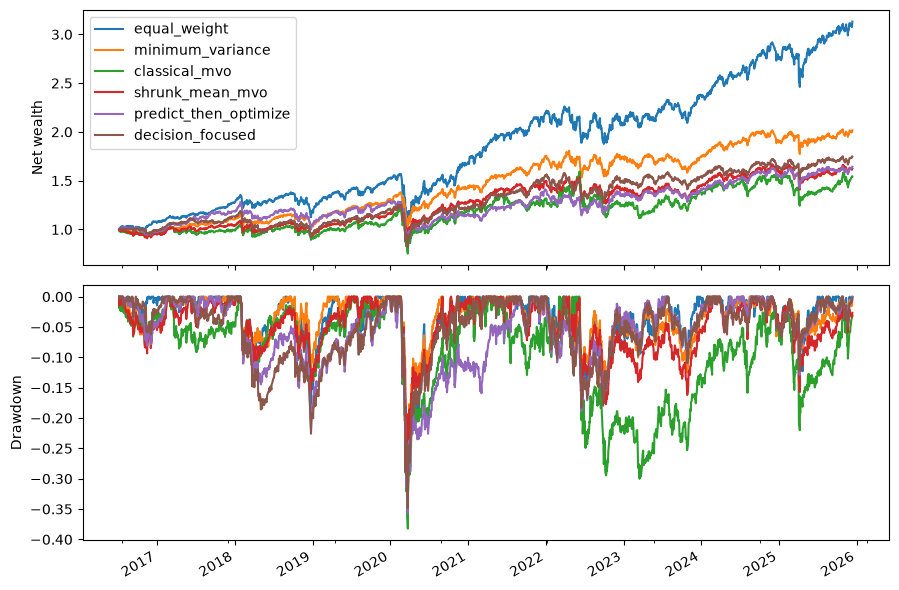

In [29]:
docs = ROOT / "docs"
docs.mkdir(exist_ok=True)
reports = {}
for seed, daily in daily_by_seed.items():
    folder = output / f"etf_seed{seed}"
    folder.mkdir(exist_ok=True)
    rows = []
    for name, targets in targets_by_seed[seed].items():
        rows.append(pd.DataFrame(targets, columns=tickers).assign(
            date=rebalance_dates, strategy=name, turnover=trades_by_seed[seed][name].to_numpy()))
    weights_table = pd.concat(rows).sort_values(["date", "strategy"])
    weights_table[["date", "strategy", "turnover", *tickers]].to_csv(folder / "weights.csv", index=False)
    daily.to_csv(folder / "daily_returns.csv", index_label="date")
    summary_by_seed[seed].to_csv(folder / "summary.csv", index_label="strategy")
    config = dict(lookback=lookback, horizon=horizon, train_periods=train_periods,
                  validation_periods=validation_periods, test_periods=test_periods,
                  epochs=epochs_stage3, risk_aversion=gamma, cost_bps=cost_bps,
                  historical_mean_scale=historical_mean_scale, seed=int(seed))
    reports[seed] = dict(config=config, source=provenance["source"], assets=tickers,
                         input_sha256=provenance["csv_sha256"],
                         test_start=str(test_dates[0].date()), test_end=str(test_dates[-1].date()),
                         test_days=len(daily), metrics=summary_by_seed[seed].T.to_dict(),
                         folds=folds_by_seed[seed])
    (folder / "backtest_report.json").write_text(json.dumps(reports[seed], indent=2) + "\n")
    wealth = (1 + daily).cumprod()
    initial = pd.DataFrame(1., index=[daily.index[0] - pd.Timedelta(days=1)], columns=daily.columns)
    wealth = pd.concat([initial, wealth])
    fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
    wealth.plot(ax=axes[0], ylabel="Net wealth")
    (wealth / wealth.cummax() - 1).plot(ax=axes[1], ylabel="Drawdown", legend=False)
    fig.tight_layout()
    fig.savefig(folder / "backtest.png", dpi=150)
    if seed == "7":
        fig.savefig(docs / "backtest_seed7.png", dpi=150)
        display(fig)
    plt.close(fig)

In [30]:
snapshot = {"data": provenance, "amortized": amortized, "backtests": reports}
(docs / "experiment_snapshot.json").write_text(json.dumps(snapshot, indent=2) + "\n")
metrics.to_csv(docs / "strategy_metrics.csv")

speed_table = pd.DataFrame(amortized).T[
    ["objective_gap_mean", "nn_single_median_ms", "solver_single_median_ms"]].astype(float)

wins = {name: sum(scores.loc["decision_focused", "annual_utility"] > scores.loc[name, "annual_utility"]
                  for scores in summary_by_seed.values())
        for name in [*baseline_names, "predict_then_optimize"]}

report_text = [
    "# Results for Nine U.S. Sector ETFs", "",
    f"Data period: {provenance['start']} to {provenance['end']} "
    f"({len(returns)} trading days).",
    f"Out-of-sample period: {test_dates[0].date()} to {test_dates[-1].date()} "
    f"({len(test_dates)} trading days).", "",

    "## Stage 1: Traditional Portfolio Strategies", "",
    baseline_summary.round(4), "",

    "## Stage 2: Approximation Accuracy and CPU Time", "",
    speed_table.round(5), "",
    "The mean objective gap measures how closely the network matches the solver. "
    "The two timing columns show the median CPU time per test instance in milliseconds.", "",

    "## Stage 3: Average Results Across Three Random Seeds", "",
    averages.round(4), "",
    f"`{averages['annual_utility'].idxmax()}` had the highest average annual net utility.", "",
    *[
        f"- Decision-focused learning achieved higher annual net utility than "
        f"`{name}` in {value} of {len(reports)} seeds."
        for name, value in wins.items()
    ],
    "", "### Historical Mean Shrinkage", "",
    f"The shrinkage baseline scales historical mean returns by {historical_mean_scale:.0%} "
    "and uses the same covariance, constraints, and trading rules as classical MVO.", "",
    f"The annual net utility difference between shrunk-mean MVO and classical MVO was "
    f"{mean_shrinkage_delta:+.4f}. "
    f"Decision-focused learning differed from shrunk-mean MVO by "
    f"{annual_utilities['decision_focused'] - annual_utilities['shrunk_mean_mvo']:+.4f}.", "",
    "This comparison measures historical mean shrinkage within classical MVO. "
    "Ledoit–Wolf covariance shrinkage is common to both portfolios.", "",
    "![Net portfolio value and drawdown](backtest_seed7.png)", "",

    "Adjusted prices for the nine surviving ETFs approximate dividend reinvestment. "
    "The backtest estimates trading costs from the value traded. "
    "Decision-focused training uses gross portfolio utility over each holding period.", "",

    "All three seeds use the same market history. Results depend on the ETFs selected "
    "and the market conditions during the sample period. "
    "The study uses no separate final holdout period.",
]

lines = []
for part in report_text:
    if isinstance(part, pd.DataFrame):
        lines.append("| Strategy | " + " | ".join(part.columns) + " |")
        lines.append("|---" + "|---:" * len(part.columns) + "|")
        for label, row in part.iterrows():
            values = ["N/A" if pd.isna(value) else str(value) for value in row]
            lines.append(f"| {label} | " + " | ".join(values) + " |")
    else:
        lines.append(part)

(docs / "experiment_report.md").write_text("\n".join(lines) + "\n")
print("Experiment report saved to", docs / "experiment_report.md")

Experiment report saved to /git_root/class_project/msml610/Fall2026/projects/UmdTask760_MSML610_Fall2026_Mean_Variance_Optimization_with_NN_1/docs/experiment_report.md
